# California Housing Dataset
## Problem framing and data-generating context

### Problem statement
We will predict the median house value of a California census block group from 1990 census-derived socioeconomic, housing, population, and geographic measurements. `MedHouseVal` is measured in hundreds of thousands of dollars and capped at 5.0, so this is prediction of the recorded historical target, not uncensored current-market valuation. The cap makes high-value errors especially important because values above $500,000 are indistinguishable.

### Unit of observation and target
- **One row:** one California census block group, typically containing about 600–3,000 people; it is not an individual household or property.
- **Target:** `MedHouseVal`, the block-group median house value in $100,000 units, top-coded at 5.0.
- **Context:** the data comes from the 1990 U.S. Census and is not representative of present-day prices.

### Data dictionary

| Column | Meaning | Role and caveat |
|---|---|---|
| `MedInc` | Median income in the block group | Aggregate socioeconomic predictor, not household income |
| `HouseAge` | Median house age | Predictor; does not directly measure condition |
| `AveRooms` | Average rooms per household | Ratio; extremes can reflect small denominators or vacation areas |
| `AveBedrms` | Average bedrooms per household | Ratio with the same small-denominator risk |
| `Population` | Block-group population | Geographic-unit count, not property or household count |
| `AveOccup` | Average household members | Aggregate occupancy ratio |
| `Latitude` | Block-group latitude | Geographic predictor and regional proxy |
| `Longitude` | Block-group longitude | Geographic predictor and regional proxy |
| `MedHouseVal` | Median house value | Target in $100,000 units, capped at 5.0 |

### Facts, assumptions, and risks

**Facts:** 20,640 rows; eight numeric predictors; no documented missing attributes; one row per census block group; data derived from the 1990 U.S. Census; `MedHouseVal` includes the known 5.0 cap.

**Assumptions:** block-group aggregates are useful predictors of the block-group median; geographic variables capture meaningful location effects; the published capped target remains the main target, while uncapped-only analysis is sensitivity analysis; relationships are historical and should not be deployed as current-market estimates.

**Risks and uncertainties:** target censoring hides differences above $500,000; nearby block groups may violate independence and make random splits optimistic; temporal shift limits present-day validity; aggregate measurements do not support individual-household conclusions; dataset construction may not represent all California markets equally.

### Testable hypotheses
1. Higher `MedInc` is associated with higher `MedHouseVal`, with diminishing returns.
2. `Latitude` and `Longitude` explain substantial geographic structure beyond non-geographic variables.
3. `AveRooms` is positively associated with value, but extreme values partly reflect small denominators.
4. `AveOccup` has a nonlinear relationship with value, with unusually high occupancy associated with lower values.
5. `HouseAge` has a weaker and potentially non-monotonic relationship with value than `MedInc`.
6. Capped rows behave differently from uncapped rows and should be compared during evaluation.

### Solution notes and validation
This framing changes the notebook from generic column exploration to a historical, block-group-level supervised-learning problem. `Latitude` and `Longitude` are geographic predictors and possible sources of spatial leakage; average room fields are ratios whose extremes need denominator-aware interpretation. Remaining questions are how geographic splits change estimated performance, how to report capped-target errors, and whether these hypotheses persist after a leakage-safe split. A reader can now identify the prediction target, row unit, historical scope, column roles, limitations, and next EDA hypotheses.

# California Housing: Data Exploration

Goal: understand the features, target variable, data quality, distributions, relationships, and possible problems before building regression models.

Questions:
- What does each feature represent?
- Which features are related to house value?
- Are there missing values or outliers?
- Which features may require scaling or transformation?
- Does a linear relationship seem reasonable?

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
housing.DESCR

'.. _california_housing_dataset:\n\nCalifornia Housing dataset\n--------------------------\n\n**Data Set Characteristics:**\n\n:Number of Instances: 20640\n\n:Number of Attributes: 8 numeric, predictive attributes and the target\n\n:Attribute Information:\n    - MedInc        median income in block group\n    - HouseAge      median house age in block group\n    - AveRooms      average number of rooms per household\n    - AveBedrms     average number of bedrooms per household\n    - Population    block group population\n    - AveOccup      average number of household members\n    - Latitude      block group latitude\n    - Longitude     block group longitude\n\n:Missing Attribute Values: None\n\nThis dataset was obtained from the StatLib:\nhttps://lib.stat.cmu.edu/datasets/houses.zip\n\nThe target variable is the median house value for California districts,\nexpressed in hundreds of thousands of dollars ($100,000).\n\nThis dataset was derived from the 1990 U.S. census, using one row per

In [5]:
df.shape

(20640, 9)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


Datasetcontains :
<li>20k+ records of houses.</li>
<li>8 input columns/features</li>
<li>Target range is (500k$ - 200k$) = 300k$</li>
<li>features with very different scale: Population</li>
<li>features with Suspicious minimum or maximum values: AveRooms,AveBedrms,AveOccup</li>


In [7]:
df.isna().sum() # no missing values

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [8]:
df.duplicated().sum() # no duplicate rows

np.int64(0)

In [9]:
df.nunique().sort_values()

HouseAge          52
Longitude        844
Latitude         862
MedHouseVal     3842
Population      3888
MedInc         12928
AveBedrms      14233
AveOccup       18841
AveRooms       19392
dtype: int64

In [10]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [11]:
df.corr() #columns 'AveRooms' and 'AveBedrms' are highly correlated. 
# latitude and longitude are also higly correlated.

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


In [12]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


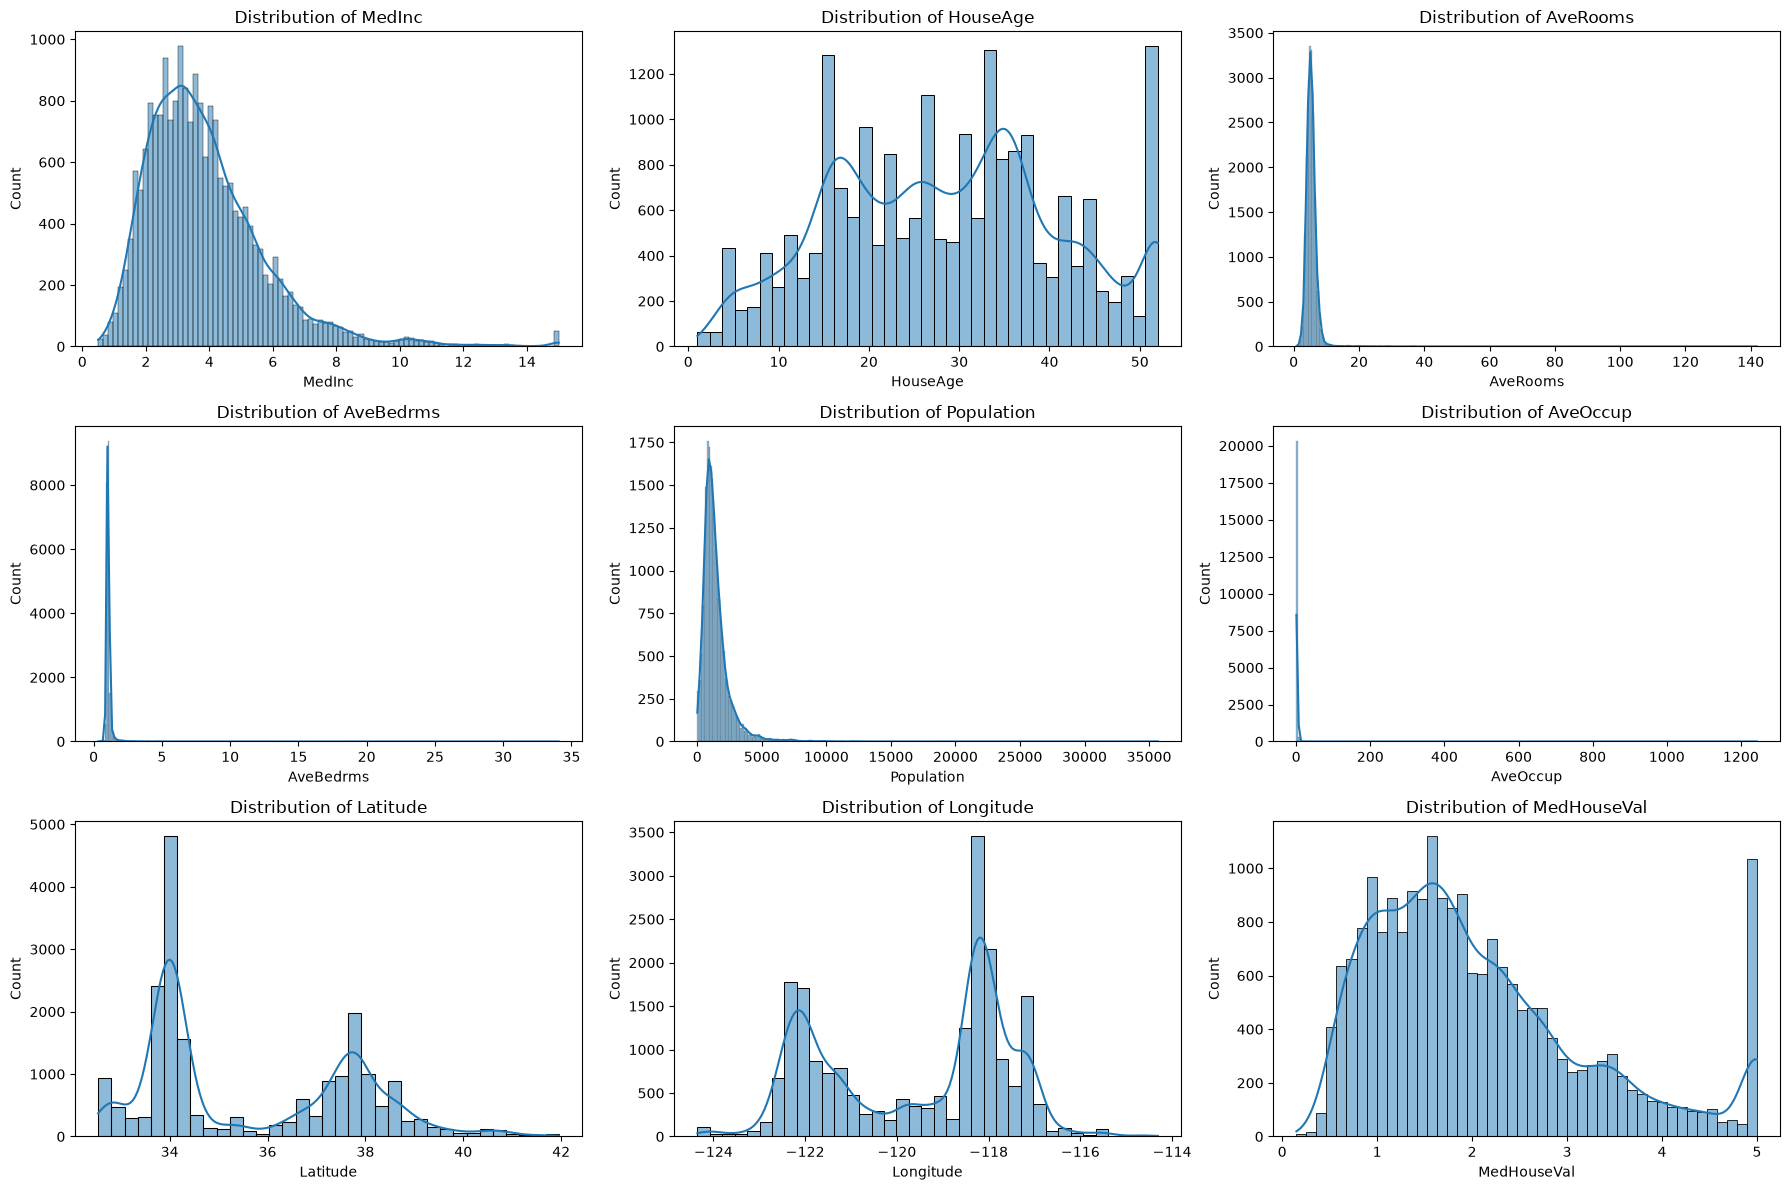

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.ravel()
for ax, column in zip(axes, df.columns):
    sns.histplot(df[column], kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

# Analyzing the target variable

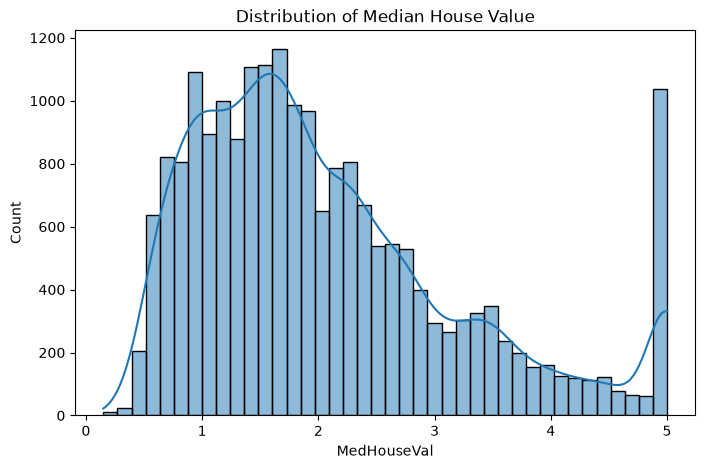

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Value")
plt.show()

In [15]:
df['MedHouseVal'].describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

# Percentage of Values at the Target's ceiling.

In [16]:
(df['MedHouseVal'] >= 5.0).mean() * 100 # checking the percentage of values capped at 5 in target column

np.float64(4.8062015503875966)

# Checking model performance before Preprocessing.

In [17]:
X = df.drop(columns=['MedHouseVal'])
y = df.iloc[:,-1]

In [18]:
from sklearn.model_selection import train_test_split
RANDOM_STATE = 2
X_train,X_test,y_train,y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# leakage-safe evaluation design

### Primary split choice
The primary evaluation uses a reproducible random 80/20 split with `RANDOM_STATE = 2`. The test set represents other California census block groups from the same 1990 snapshot, not future housing markets. This keeps the first modeling workflow simple and provides a stable baseline for comparing models.

The random split may be optimistic because nearby block groups can occur in both training and test sets and share spatial structure. A spatial holdout or spatial cross-validation would be a stronger alternative for measuring performance on geographically distinct areas, but it can introduce regional distribution shift and reduce the effective sample size. A later temporal evaluation using a newer census would be needed to assess future-year deployment; this dataset does not provide that test population.

### Test-set boundary and validation
The test set is created once and remains untouched during feature selection, preprocessing decisions, model comparison, and hyperparameter tuning. Validation must use only the training portion, through a validation split or cross-validation, and the final test score is reported only after those decisions are complete. The current notebook's baseline model uses the held-out test set only for its final evaluation.

### Leakage controls
- Split `X` and `y` before model fitting; `MedHouseVal` must never appear in the feature matrix or in target-derived features.
- Fit scaling, imputation, transformations, feature selection, and outlier thresholds on training data only, then transform validation and test data.
- Do not use test performance to select features, remove observations, choose transformations, or tune hyperparameters.
- Do not construct neighborhood features using target values from held-out rows.
- Treat the 5.0 target cap as a property of the published target, not as a feature; keep capped-row handling consistent across splits.

### Limitations
This random holdout estimates generalization to another random 1990 block group and does not establish temporal stability or performance in geographically unseen regions. The spatial alternative should be revisited if the deployment goal changes from same-population estimation to prediction for new areas.

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
lr = LinearRegression()

In [20]:
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score(y_test,y_pred)

0.6013853272055154

In [21]:
df_uncapped = df[df['MedHouseVal'] < 5.0].copy()
df_uncapped.shape


(19648, 9)

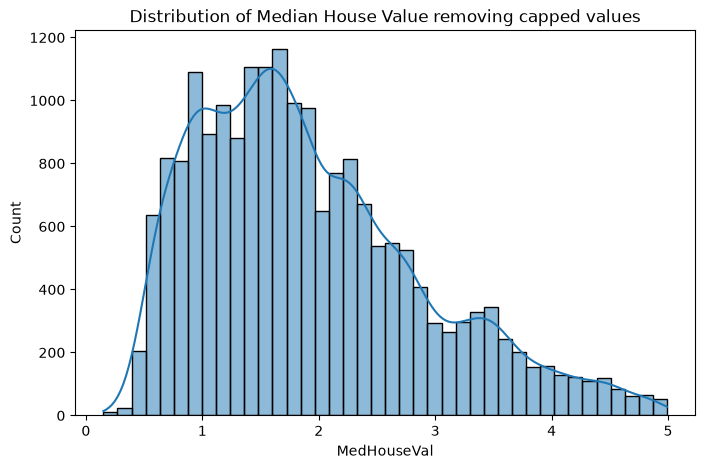

In [22]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_uncapped, x="MedHouseVal", bins=40, kde=True)
plt.title("Distribution of Median House Value removing capped values")
plt.show()

In [23]:
feature_columns = df.columns.drop("MedHouseVal")

train_indices, test_indices = train_test_split(
    df.index,
    test_size=0.2,
    random_state=2
)

# Model 1: trained on all original training rows
model_all = LinearRegression()
model_all.fit(
    df.loc[train_indices, feature_columns],
    df.loc[train_indices, "MedHouseVal"]
)

# Model 2: trained only on uncapped rows from the same training set
uncapped_train_indices = train_indices[
    df.loc[train_indices, "MedHouseVal"] < 5.0
]

model_uncapped = LinearRegression()
model_uncapped.fit(
    df.loc[uncapped_train_indices, feature_columns],
    df.loc[uncapped_train_indices, "MedHouseVal"]
)

# Both models evaluated on the exact same original test set
X_test_common = df.loc[test_indices, feature_columns]
y_test_common = df.loc[test_indices, "MedHouseVal"]

r2_all = r2_score(
    y_test_common,
    model_all.predict(X_test_common)
)

r2_uncapped = r2_score(
    y_test_common,
    model_uncapped.predict(X_test_common)
)

print("R², model trained on all rows:", r2_all)
print("R², model trained without capped training rows:", r2_uncapped)

R², model trained on all rows: 0.6013853272055154
R², model trained without capped training rows: 0.5959199044689703


In [24]:
uncapped_test_indices = test_indices[
    df.loc[test_indices, "MedHouseVal"] < 5.0
]

X_uncapped_test = df.loc[uncapped_test_indices, feature_columns]
y_uncapped_test = df.loc[uncapped_test_indices, "MedHouseVal"]

print(
    "All-row model on uncapped test rows:",
    r2_score(y_uncapped_test, model_all.predict(X_uncapped_test))
)

print(
    "Uncapped model on uncapped test rows:",
    r2_score(y_uncapped_test, model_uncapped.predict(X_uncapped_test))
)

All-row model on uncapped test rows: 0.5776375685145484
Uncapped model on uncapped test rows: 0.5827825015218753


## Conclusion: keep the original target for the main model

The value `5.0` in `MedHouseVal` is a capped target value, not a separate column and not necessarily an ordinary outlier. In this dataset, it represents a median house value of at least 500,000 dollars, but values above that level are recorded as `5.0`.

For the main model, keep the target variable and all observations intact. This preserves the original prediction problem and allows the model to learn from the complete dataset.

The capped-row experiment was useful as a sensitivity analysis:

- On the same original test set, the model trained on all rows achieved an R² of `0.6014`, compared with `0.5959` for the model trained without capped training rows.
- On only the uncapped test rows, the all-row model achieved `0.5776`, compared with `0.5828` for the uncapped-training model.

Removing capped training rows helped slightly for uncapped houses but reduced performance on the complete test set. Therefore, there is no strong reason to remove those rows from the primary analysis. Keep this experiment as a comparison, and use cross-validation for a more reliable estimate before choosing a final model.

If the goal is specifically to predict values only below the cap, the uncapped experiment can be treated as a separate modeling problem. Otherwise, keep `MedHouseVal` intact. 

## Bivariate Analysis:
 Analyzing the relationship between each feature and the target.



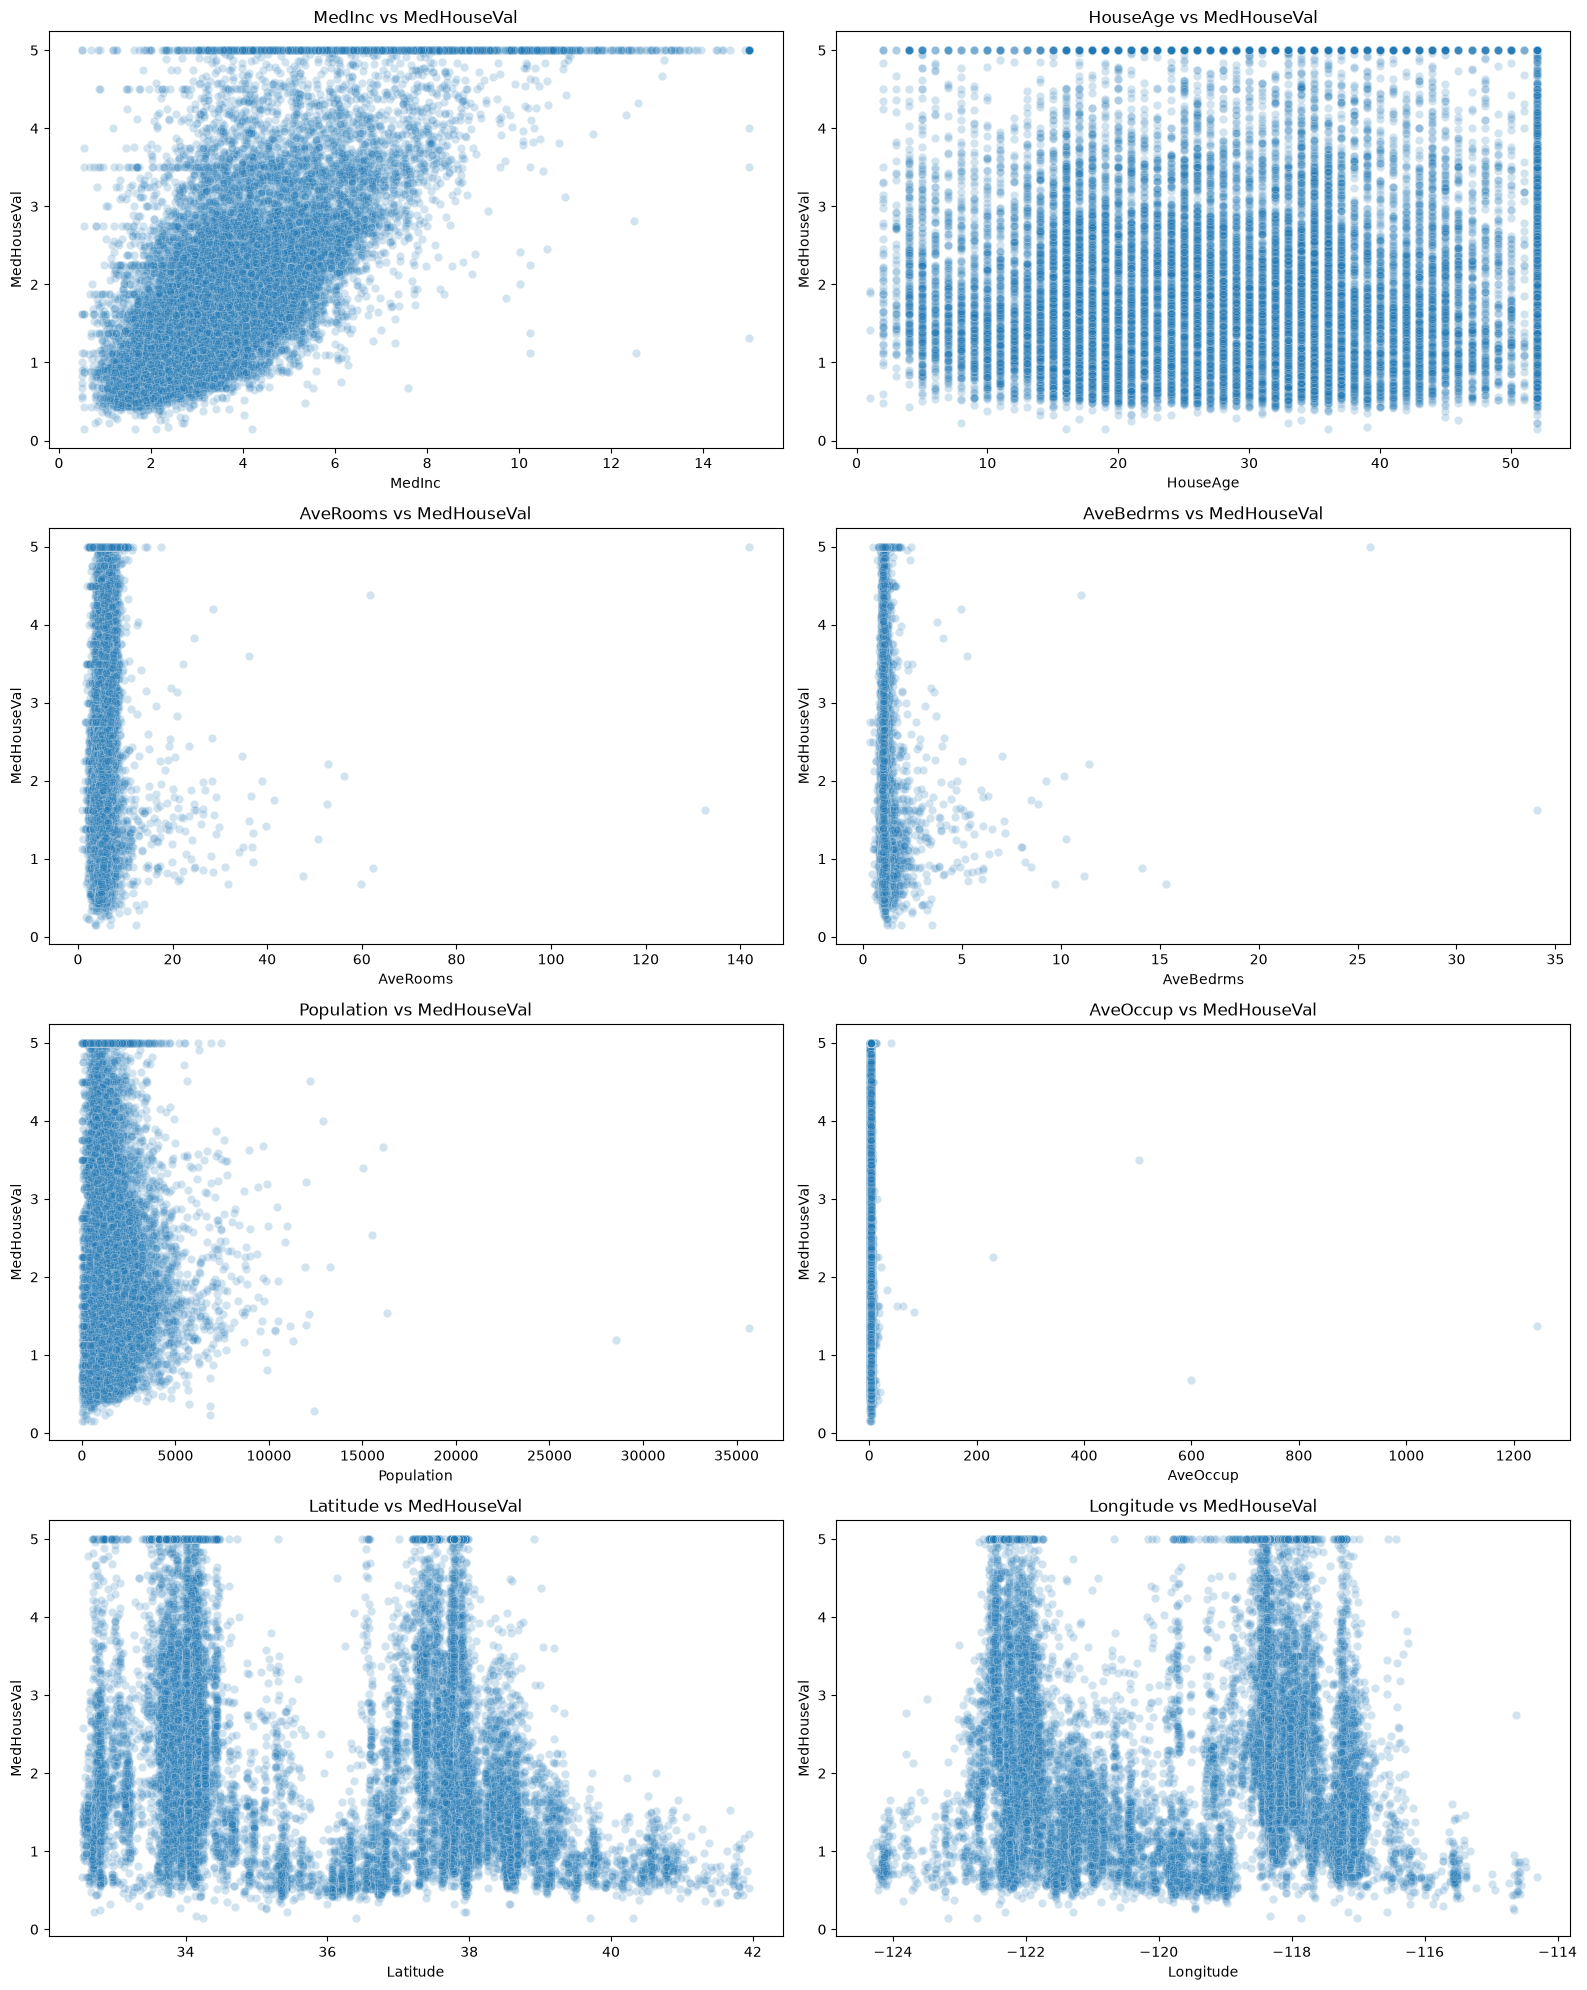

In [25]:
features = df.columns.drop("MedHouseVal")

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.ravel()

for ax, feature in zip(axes, features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="MedHouseVal",
        alpha=0.2,
        ax=ax
    )
    ax.set_title(f"{feature} vs MedHouseVal")

plt.tight_layout()
plt.show()

# Investigating the extreme values in AveRooms,AveBedrms and Aveoccup

Your goal is to answer three questions:
1. How extreme are the values?
2. Are they genuine observations or possible data problems?
3. Do they have enough influence on your Linear Regression model to warrant further investigation?

In [26]:
df[["AveRooms", "AveBedrms", "AveOccup","Population"]].describe(percentiles=[0.01, 0.50, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
AveRooms,20640.0,5.429000,2.474173,0.846154,2.581133,5.229129,10.357033,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,0.872840,1.048780,2.127541,34.066667
AveOccup,20640.0,3.070655,10.386050,0.692308,1.536686,2.818116,5.394812,1243.333333
Population,20640.0,1425.476744,1132.462122,3.000000,88.000000,1166.000000,5805.830000,35682.000000


# observation


# 99 percentile of values in :
 ### AvgRooms <= 10.357
 ### AveBedrms <= 2.12
 ### AvgOccup <= 5.39, 
 ### Population <= 5805.83
 but thier maximum values are way too extreme.<br>
 AvgRooms max  is 14x fold greater than the 99 percentile value.<br>
 similarly, AveBedrms is approx. 17x fold greater. <br>
 AveOccup is approx. 250x fold greater.<br>
 and Population is 7x fold greater than the 99 percentile value. <br>
 so these values are way too extreme from the rest of the data.



In [27]:
df[df['AveRooms'] > 10.357033].shape

(207, 9)

In [28]:
df['AveRooms'].nlargest(10)

1914     141.909091
1979     132.533333
12447     62.422222
1913      61.812500
11862     59.875000
1912      56.269231
9676      52.848214
11707     52.690476
2395      50.837838
1240      47.515152
Name: AveRooms, dtype: float64

In [29]:
df[df['AveBedrms'] > 2.127541].shape

(207, 9)

In [30]:
df['AveBedrms'].nlargest(10)

1979     34.066667
1914     25.636364
11862    15.312500
12447    14.111111
9676     11.410714
1240     11.181818
1913     11.000000
2395     10.270270
1912     10.153846
1102      9.703704
Name: AveBedrms, dtype: float64

In [31]:
df[['AveRooms','AveBedrms']].sort_values(by='AveBedrms',ascending=False).head(10)

,AveRooms,AveBedrms
1979,132.533333,34.066667
1914,141.909091,25.636364
11862,59.875000,15.312500
12447,62.422222,14.111111
9676,52.848214,11.410714
1240,47.515152,11.181818
1913,61.812500,11.000000
2395,50.837838,10.270270
1912,56.269231,10.153846
1102,31.777778,9.703704


In [32]:
df['AveOccup'].nlargest(10)

19006    1243.333333
3364      599.714286
16669     502.461538
13034     230.172414
9172       83.171429
12104      63.750000
16420      51.400000
8874       41.214286
13366      33.952941
5986       21.333333
Name: AveOccup, dtype: float64

In [33]:
df.nlargest(20, 'AveOccup')[
    ['AveOccup', 'AveRooms', 'AveBedrms',
     'Population', 'HouseAge', 'MedHouseVal']
]

,AveOccup,AveRooms,AveBedrms,Population,HouseAge,MedHouseVal
19006,1243.333333,3.166667,0.833333,7460.0,45.0,1.37500
3364,599.714286,5.142857,1.142857,4198.0,36.0,0.67500
16669,502.461538,9.076923,1.307692,6532.0,46.0,3.50000
13034,230.172414,8.275862,1.517241,6675.0,52.0,2.25000
9172,83.171429,5.123810,0.933333,8733.0,5.0,1.54600
12104,63.750000,7.600000,0.950000,1275.0,8.0,1.62500
16420,51.400000,5.366667,0.900000,1542.0,26.0,1.62500
8874,41.214286,7.285714,1.214286,1154.0,52.0,5.00001
13366,33.952941,5.258824,1.117647,2886.0,36.0,1.83300
5986,21.333333,4.500000,1.206349,2688.0,52.0,2.12500


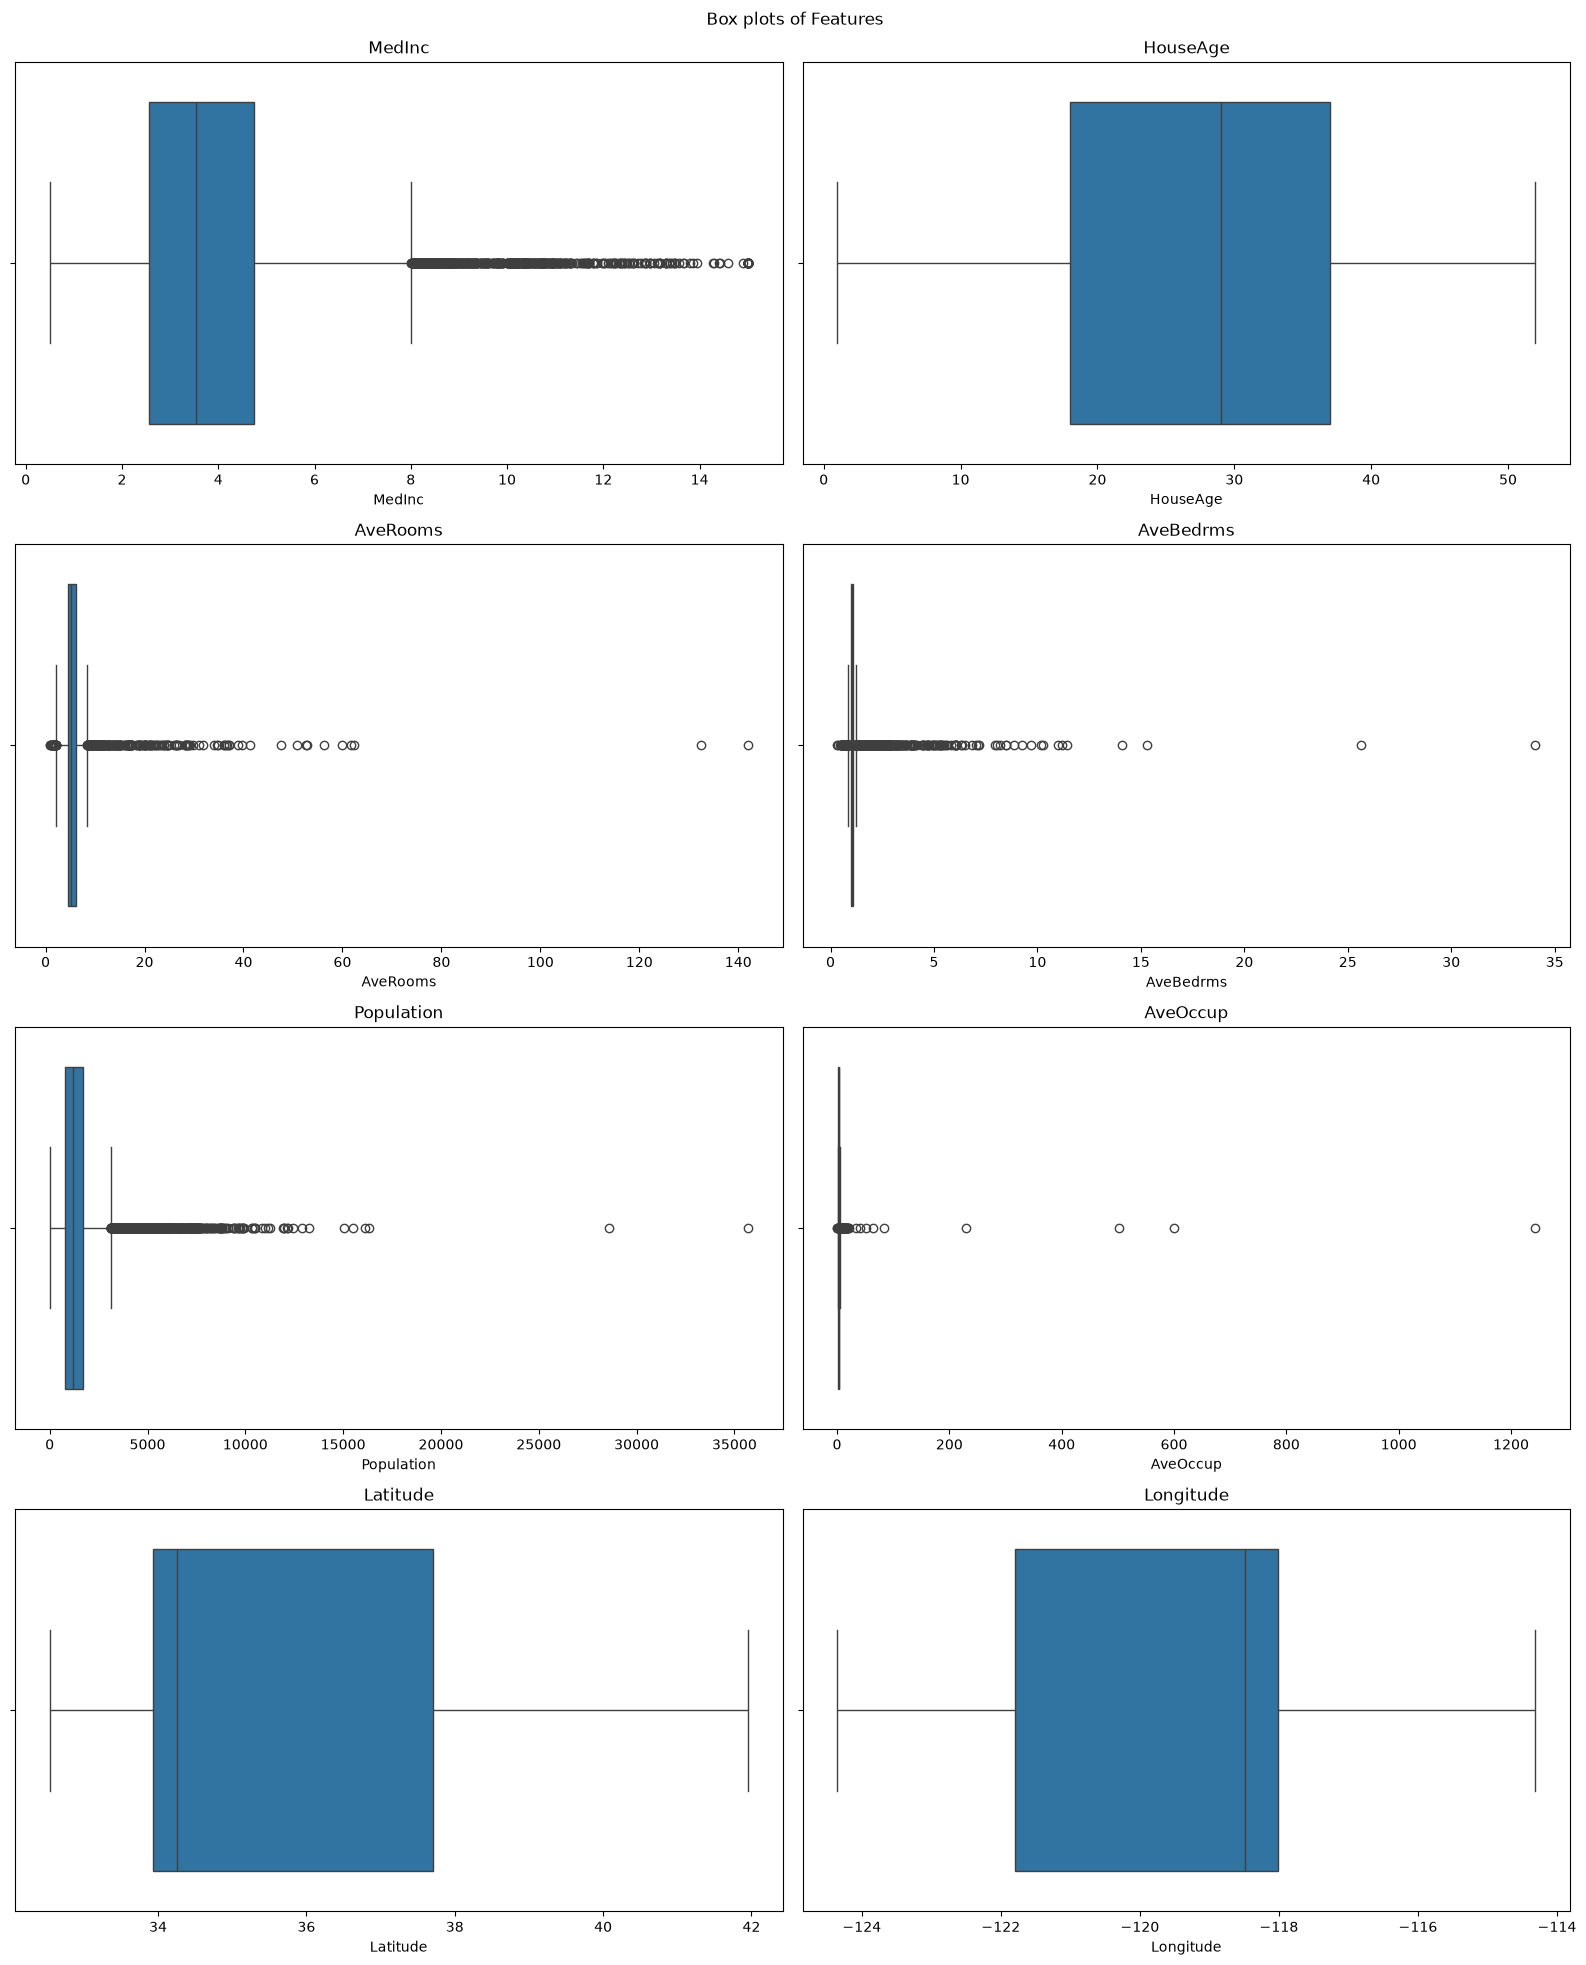

In [34]:
features = df.columns.drop("MedHouseVal")

fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.ravel()
for ax,feature in zip(axes,features):
    sns.boxplot(data=df,x=feature,ax=ax)
    ax.set_title(f"{feature}")
plt.suptitle("Box plots of Features\n")    
plt.tight_layout()
plt.show()

# Data profile

In [35]:
profile = pd.DataFrame({
    "dtype": X_train.dtypes,
    "missing": X_train.isna().sum(),
    "unique": X_train.nunique(),
    "min": X_train.min(),
    "q01": X_train.quantile(0.01),
    "q25": X_train.quantile(0.25),
    "median": X_train.quantile(0.50),
    "q75": X_train.quantile(0.75),
    "q99": X_train.quantile(0.99),
    "max": X_train.max(),
    "skew": X_train.skew()
})

profile

,dtype,missing,unique,min,q01,q25,median,q75,q99,max,skew
MedInc,float64,0,10900,0.499900,1.077341,2.562500,3.531300,4.733225,10.547041,15.000100,1.634607
HouseAge,float64,0,52,1.000000,4.000000,18.000000,29.000000,37.000000,52.000000,52.000000,0.062843
AveRooms,float64,0,15698,0.846154,2.577291,4.441027,5.224884,6.047464,10.190260,132.533333,17.500514
AveBedrms,float64,0,11966,0.333333,0.870436,1.006231,1.048420,1.099243,2.096506,34.066667,33.307257
Population,float64,0,3658,3.000000,88.000000,788.000000,1168.000000,1738.000000,5857.690000,35682.000000,5.250859
AveOccup,float64,0,15316,0.692308,1.545038,2.430380,2.821348,3.290106,5.404066,1243.333333,98.842632
Latitude,float64,0,840,32.540000,32.680000,33.930000,34.250000,37.710000,40.630000,41.950000,0.473196
Longitude,float64,0,828,-124.350000,-123.220000,-121.790000,-118.490000,-118.010000,-116.250000,-114.310000,-0.298204


# Outlier Summary

In [36]:
outlier_summary = []

for column in X_train.columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (X_train[column] < lower) | (X_train[column] > upper)

    outlier_summary.append({
        "feature": column,
        "lower_bound": lower,
        "upper_bound": upper,
        "flagged_count": mask.sum(),
        "flagged_percent": mask.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,feature,lower_bound,upper_bound,flagged_count,flagged_percent
0,MedInc,-0.693588,7.989313,555,3.361192
1,HouseAge,-10.500000,65.500000,0,0.000000
2,AveRooms,2.031371,8.457119,412,2.495155
3,AveBedrms,0.866712,1.238762,1143,6.922238
4,Population,-637.000000,3163.000000,951,5.759448
5,AveOccup,1.140790,4.579696,571,3.458091
6,Latitude,28.260000,43.380000,0,0.000000
7,Longitude,-127.460000,-112.340000,0,0.000000


In [37]:
iqr_flags = pd.DataFrame(index=X_train.index)

for column in feature_columns:
    q1 = X_train[column].quantile(0.25)
    q3 = X_train[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_flags[column] = (
        (X_train[column] < lower) |
        (X_train[column] > upper)
    )
iqr_flags["n_flagged_features"] = iqr_flags.sum(axis=1)
print("Rows flagged by at least one feature:",
      (iqr_flags["n_flagged_features"] > 0).sum())

print("Percentage of training rows flagged:",
      (iqr_flags["n_flagged_features"] > 0).mean() * 100)

iqr_flags["n_flagged_features"].value_counts().sort_index()
# iqr_flags.sample(5)

Rows flagged by at least one feature: 3038
Percentage of training rows flagged: 18.398740310077518


n_flagged_features
0    13474
1     2482
2      521
3       32
4        3
Name: count, dtype: int64

3 rows are extreme across 4 variables and 32 rows are extreme across 3 variables.

In [38]:
iqr_flags["n_flagged_features"].sort_values(ascending=False).head(20).index 
# the rows with these index are the ones with most extreme values across all the feature /variables.

Index([10405, 10519, 19006, 12077, 14803, 12375, 17891, 12374, 15183,  4352,
        6226,  1645, 12430, 20428, 12201, 12084,  2510, 20121, 11849, 20335],
      dtype='int64')

# Inspecting the most suspicious rows in context

In [39]:
most_flagged_indices = (
    iqr_flags["n_flagged_features"]
    .sort_values(ascending=False)
    .head(20)
    .index
)

df.loc[
    most_flagged_indices,
    [
        "MedInc", "HouseAge", "AveRooms", "AveBedrms",
        "Population", "AveOccup", "Latitude",
        "Longitude", "MedHouseVal"
    ]
]

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
10405,10.9704,6.0,10.558140,2.372093,213.0,4.953488,33.69,-117.53,4.83300
10519,10.1122,2.0,8.786655,1.275680,3550.0,3.116769,33.57,-117.68,5.00001
19006,10.2264,45.0,3.166667,0.833333,7460.0,1243.333333,38.32,-121.98,1.37500
12077,6.2308,2.0,8.801008,1.373804,5964.0,3.004534,33.87,-117.64,2.57900
14803,8.7991,10.0,9.287154,1.457179,1900.0,2.392947,32.63,-117.13,4.78500
12375,4.0840,7.0,9.658791,1.911538,3581.0,1.967582,33.74,-116.38,1.94500
17891,3.3750,34.0,11.384615,2.153846,132.0,10.153846,37.40,-121.93,0.67500
12374,3.3799,6.0,10.860423,2.036020,4176.0,1.880234,33.78,-116.36,2.39300
15183,7.2731,4.0,8.861439,1.343750,5613.0,3.309552,33.02,-117.15,4.50400
4352,15.0001,37.0,8.659574,1.425532,100.0,2.127660,34.10,-118.37,5.00001


The Obeservation tells that all values are mathematically possible.
and rows do have plausible combination of related variables.

These observations are statistically extreme, but they have not yet been proven invalid or influential.<br> They will remain in the primary dataset while their modeling influence is investigated separately.



# EDA conclusion 
The IQR rule flags a number of extreme feature values, especially in AveRooms, AveBedrms, and AveOccup. These variables are aggregate ratios, so extreme values may result from small denominators or unusual block groups rather than data corruption. No impossible negative values or missing values were found. Because statistical extremeness alone does not establish invalidity, the rows will remain in the primary dataset. Their influence will be assessed later through model diagnostics and sensitivity analysis. Candidate transformations or robust alternatives will be compared against the unchanged baseline rather than applied automatically.



## Feature-by-feature distribution diagnoses

| Feature | Distribution and support | Suspicious-value assessment | Candidate transformation hypothesis |
|---|---|---|---|
| `MedInc` | Positive, right-skewed income measure with a long upper tail | Values are within the published dataset support; high values are rare, not automatically invalid | Compare unchanged and `log1p` versions in training-only pipelines |
| `HouseAge` | Bounded numeric feature with integer-like values from 1 to 52 | The upper bound is a dataset support limit, not evidence of a bad row | Keep unchanged initially; test nonlinear treatment if feature analysis supports it |
| `AveRooms` | Positive ratio with a strong right tail and very large maximum values | Extreme rows are mathematically possible and may reflect unusual block groups or small denominators; no invalid negative values were found | Compare unchanged and `log1p` versions; do not clip automatically |
| `AveBedrms` | Positive ratio concentrated near its center with a long right tail | Large values are unusual and were inspected with related room fields; they are not proven data errors | Compare unchanged and `log1p` versions; retain rows for the primary analysis |
| `Population` | Positive, right-skewed count with a heavy upper tail | Large block-group populations can be legitimate; no impossible values were identified | Compare unchanged and `log1p` versions if a baseline supports the hypothesis |
| `AveOccup` | Positive ratio with an exceptionally heavy right tail | Very large values are the most suspicious feature extremes, but contextual inspection did not prove corruption | Test a training-derived cap or robust transformation only as a sensitivity analysis |
| `Latitude` | Bounded geographic coordinate covering the dataset region | Values are plausible geographic measurements, not ordinary continuous outliers | Keep unchanged; consider spatial validation separately from transformation |
| `Longitude` | Bounded geographic coordinate covering the dataset region | Values are plausible geographic measurements, not ordinary continuous outliers | Keep unchanged; consider spatial validation separately from transformation |

The profile table, histograms, boxplots, IQR flags, and contextual row inspection are consistent: unusual does not mean invalid. No rows were removed, imputed, clipped, or transformed during this EDA stage, so the original training profile remains the baseline for later comparisons. Candidate transformations are hypotheses to evaluate inside leakage-safe pipelines, not cleaning decisions.

# Target Distribution ,Censoring and Business related error

In [40]:
target_summary = df["MedHouseVal"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

target_summary

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
1%           0.500000
5%           0.662000
25%          1.196000
50%          1.797000
75%          2.647250
95%          4.898100
99%          5.000010
max          5.000010
Name: MedHouseVal, dtype: float64

In [41]:
df["MedHouseVal"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

0.01    0.50000
0.05    0.66200
0.25    1.19600
0.50    1.79700
0.75    2.64725
0.95    4.89810
0.99    5.00001
Name: MedHouseVal, dtype: float64

In [42]:
ceiling_summary = pd.Series({
    "exactly_5": (df["MedHouseVal"] == 5.0).sum(),
    "at_or_above_5": (df["MedHouseVal"] >= 5.0).sum(),
    "at_or_above_4_9": (df["MedHouseVal"] >= 4.9).sum(),
    "exactly_5_percent": (df["MedHouseVal"] == 5.0).mean() * 100,
    "at_or_above_5_percent": (df["MedHouseVal"] >= 5.0).mean() * 100,
})

ceiling_summary

exactly_5                  27.000000
at_or_above_5             992.000000
at_or_above_4_9          1032.000000
exactly_5_percent           0.130814
at_or_above_5_percent       4.806202
dtype: float64

In [43]:
df["income_band"] = pd.qcut(
    df["MedInc"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

df.groupby("income_band", observed=True)["MedHouseVal"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)


,count,mean,median,std,min,max
income_band,,,,,,
Q1,4130,1.184027,0.992,0.702965,0.14999,5.00001
Q2,4131,1.570300,1.435,0.763139,0.17500,5.00001
Q3,4123,1.938895,1.755,0.881771,0.40000,5.00001
Q4,4128,2.300291,2.122,0.921399,0.14999,5.00001
Q5,4128,3.349910,3.223,1.101078,0.47500,5.00001


### Income-band interpretation

- The five income bands contain approximately equal numbers of block groups because they are quantile-based.
- Median house value increases as block-group median income increases, supporting a positive association between `MedInc` and `MedHouseVal`.
- The mean is above the median in every band, indicating right-skewed target values within each income group.
- The minimum values show that higher-income block groups can still have relatively low recorded median house values, so income does not determine value by itself.
- The repeated maximum near `5.0` across bands is consistent with the known upper cap in `MedHouseVal`; it does not mean that households in those bands necessarily purchased expensive homes.

These grouped summaries support the income hypothesis, but they do not establish causality or account for geography, age, occupancy, or other predictors.

## Target-analysis conclusion

`MedHouseVal` is right-skewed and bounded by a known recording ceiling near 5.0, so the upper tail cannot be interpreted as an ordinary unconstrained maximum. Report the target in its original units: one unit equals $100,000 of recorded median block-group house value. Use MAE as an interpretable primary error measure and RMSE as a secondary measure that emphasizes large errors; retain R-squared as a relative goodness-of-fit statistic rather than the only decision metric.

The ceiling analysis should be repeated on the training and held-out partitions when model evaluation begins. Do not remove or transform capped rows for the main problem. Treat uncapped-only modeling as a sensitivity analysis because the original task is to predict the recorded target, including its cap.

Remaining target-task work: record the quantitative distribution and ceiling results from the cells above, compare errors on capped versus uncapped rows after a leakage-safe baseline is established, and explain how the metric choice reflects the intended use.

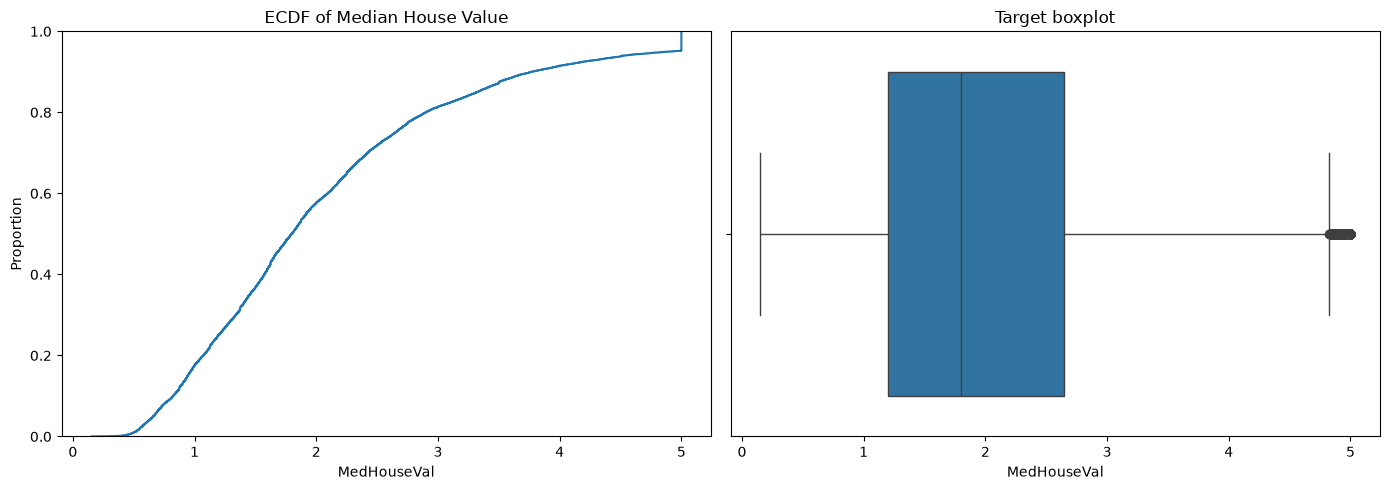

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.ecdfplot(data=df, x="MedHouseVal", ax=axes[0])
axes[0].set_title("ECDF of Median House Value")

sns.boxplot(x=df["MedHouseVal"], ax=axes[1])
axes[1].set_title("Target boxplot")

plt.tight_layout()
plt.show()

In [45]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_test_pred = model_all.predict(X_test_common)

test_metric_summary = pd.Series({
    "MAE": mean_absolute_error(y_test_common, y_test_pred),
    "RMSE": mean_squared_error(y_test_common, y_test_pred) ** 0.5,
    "R2": r2_score(y_test_common, y_test_pred),
})

test_metric_summary

MAE     0.535829
RMSE    0.732764
R2      0.601385
dtype: float64

In [46]:
test_results = pd.DataFrame({
    "actual": y_test_common,
    "predicted": y_test_pred,
})

test_results["target_group"] = np.where(
    test_results["actual"] >= 5.0,
    "capped",
    "uncapped",
)

def regression_metrics(group):
    return pd.Series({
        "count": len(group),
        "MAE": mean_absolute_error(group["actual"], group["predicted"]),
        "RMSE": mean_squared_error(group["actual"], group["predicted"]) ** 0.5,
        "R2": r2_score(group["actual"], group["predicted"]),
    })

subgroup_metric_summary = test_results.groupby(
    "target_group", observed=True
).apply(regression_metrics, include_groups=False)

subgroup_metric_summary

,count,MAE,RMSE,R2
target_group,,,,
capped,209.0,1.508425,1.776290,-9.746996e+11
uncapped,3919.0,0.483961,0.630327,5.776376e-01


## Metric justification

The primary prediction objective is to estimate the recorded median value of a census block group in the dataset's original units, where one target unit equals $100,000. Therefore, the primary metric is **MAE**: it reports the typical absolute prediction error directly in target units and gives every block group equal weight. For example, an MAE of 0.50 corresponds to an average absolute error of $50,000 in recorded target units.

**RMSE** is a secondary metric because squaring errors gives large mistakes more weight. It is useful when a model that makes a few very large errors is less acceptable, but it is more sensitive to the target ceiling and unusual observations than MAE. Reporting both shows whether conclusions are driven by typical error or by a smaller number of large errors.

**R-squared** is supplementary: it measures the fraction of target variance explained relative to a mean-prediction baseline, but it is not expressed in dollars and can hide practically large errors. It can also be affected by the target's capped upper tail, so it should not be used alone to select a model.

The capped and uncapped subgroup metrics are diagnostic rather than separate optimization targets. Capped rows represent values at or above the recording ceiling, so their errors cannot reveal how far above the ceiling the true value would have been. The main model therefore keeps capped rows and reports overall MAE, RMSE, and R-squared, while subgroup results make the ceiling's effect visible.

# Studying Feature to Target relationships

In [47]:
df['AveBedrms'].corr(df['MedHouseVal'],)

np.float64(-0.04670051296948688)

In [48]:
df.corr(numeric_only=True,method='pearson')['MedHouseVal'].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64

In [49]:
df.corr(numeric_only=True,method='spearman')['MedHouseVal'].sort_values(ascending=False)

MedHouseVal    1.000000
MedInc         0.676778
AveRooms       0.263367
HouseAge       0.074855
Population     0.003839
Longitude     -0.069667
AveBedrms     -0.125187
Latitude      -0.165739
AveOccup      -0.256594
Name: MedHouseVal, dtype: float64

In [50]:
eda_train = X_train.copy()
eda_train["MedHouseVal"] = y_train

# quantile-binned target summaries
Correlation only measures an overall association. Binned summaries reveal whether the relationship is linear, monotonic, or nonlinear.



In [51]:
features = X_train.columns

binned_summaries = {}

for feature in features:
    binned = pd.qcut(
        eda_train[feature],
        q=10,
        labels=['Q1','Q2','Q3','Q4','Q5','Q6','Q7','Q8','Q9','Q10'],
        duplicates="drop"
    )

    summary = eda_train.groupby(
        binned,
        observed=True
    )["MedHouseVal"].agg(
        count="count",
        mean="mean",
        median="median",
        std="std"
    )

    binned_summaries[feature] = summary
    print(f"\n--- {feature} ---")
    display(summary)


--- MedInc ---


,count,mean,median,std
MedInc,,,,
Q1,1653,1.093573,0.901,0.720505
Q2,1651,1.262812,1.125,0.671591
Q3,1651,1.477406,1.368,0.710434
Q4,1651,1.651965,1.505,0.775452
Q5,1657,1.860174,1.680,0.846162
Q6,1644,2.008633,1.800,0.906993
Q7,1651,2.204459,1.995,0.938638
Q8,1651,2.399929,2.226,0.893819
Q9,1651,2.795566,2.611,0.927126



--- HouseAge ---


,count,mean,median,std
HouseAge,,,,
Q1,1656,1.955720,1.6675,1.023798
Q2,2154,1.890853,1.6455,0.972819
Q3,1247,1.932817,1.6670,1.097088
Q4,1849,2.075488,1.8770,1.144142
Q5,1641,2.083677,1.8740,1.150403
Q6,1704,2.023225,1.7730,1.139953
Q7,1882,2.100275,1.8555,1.134266
Q8,1271,2.056475,1.6910,1.239328
Q9,1531,2.039345,1.7290,1.159433



--- AveRooms ---


...

,count,mean,median,std
AveOccup,,,,
Q1,1652,2.645092,2.389,1.347693
Q2,1651,2.350695,2.150,1.244188
Q3,1651,2.235857,2.000,1.230070
Q4,1651,2.195715,1.953,1.215048
Q5,1651,2.175090,1.958,1.174771
Q6,1651,2.097429,1.890,1.130699
Q7,1651,2.000140,1.821,1.047950
Q8,1651,1.897128,1.746,0.972802
Q9,1651,1.622660,1.546,0.817466



--- Latitude ---


,count,mean,median,std
Latitude,,,,
Q1,1665,2.071527,1.7380,1.130209
Q2,1655,2.371678,2.1670,1.007947
Q3,1652,1.909238,1.6610,0.938375
Q4,1668,2.240250,1.7465,1.252077
Q5,1638,2.490974,2.2400,1.151416
Q6,1634,1.623872,1.3200,1.074558
Q7,1672,2.285009,2.2480,1.313264
Q8,1667,2.488779,2.3530,1.177286
Q9,1612,1.967939,1.6610,1.048607



--- Longitude ---


,count,mean,median,std
Longitude,,,,
Q1,1664,2.417876,2.3600,1.299689
Q2,1644,2.476423,2.2500,1.231236
Q3,1674,1.917193,1.7665,1.008155
Q4,1626,1.355599,1.2460,0.625535
Q5,1656,1.806847,1.3020,1.321497
Q6,1660,2.878633,2.6725,1.247344
Q7,1654,1.853310,1.6290,0.875092
Q8,1652,2.259531,1.9770,0.886381
Q9,1630,2.078500,1.7995,1.131536


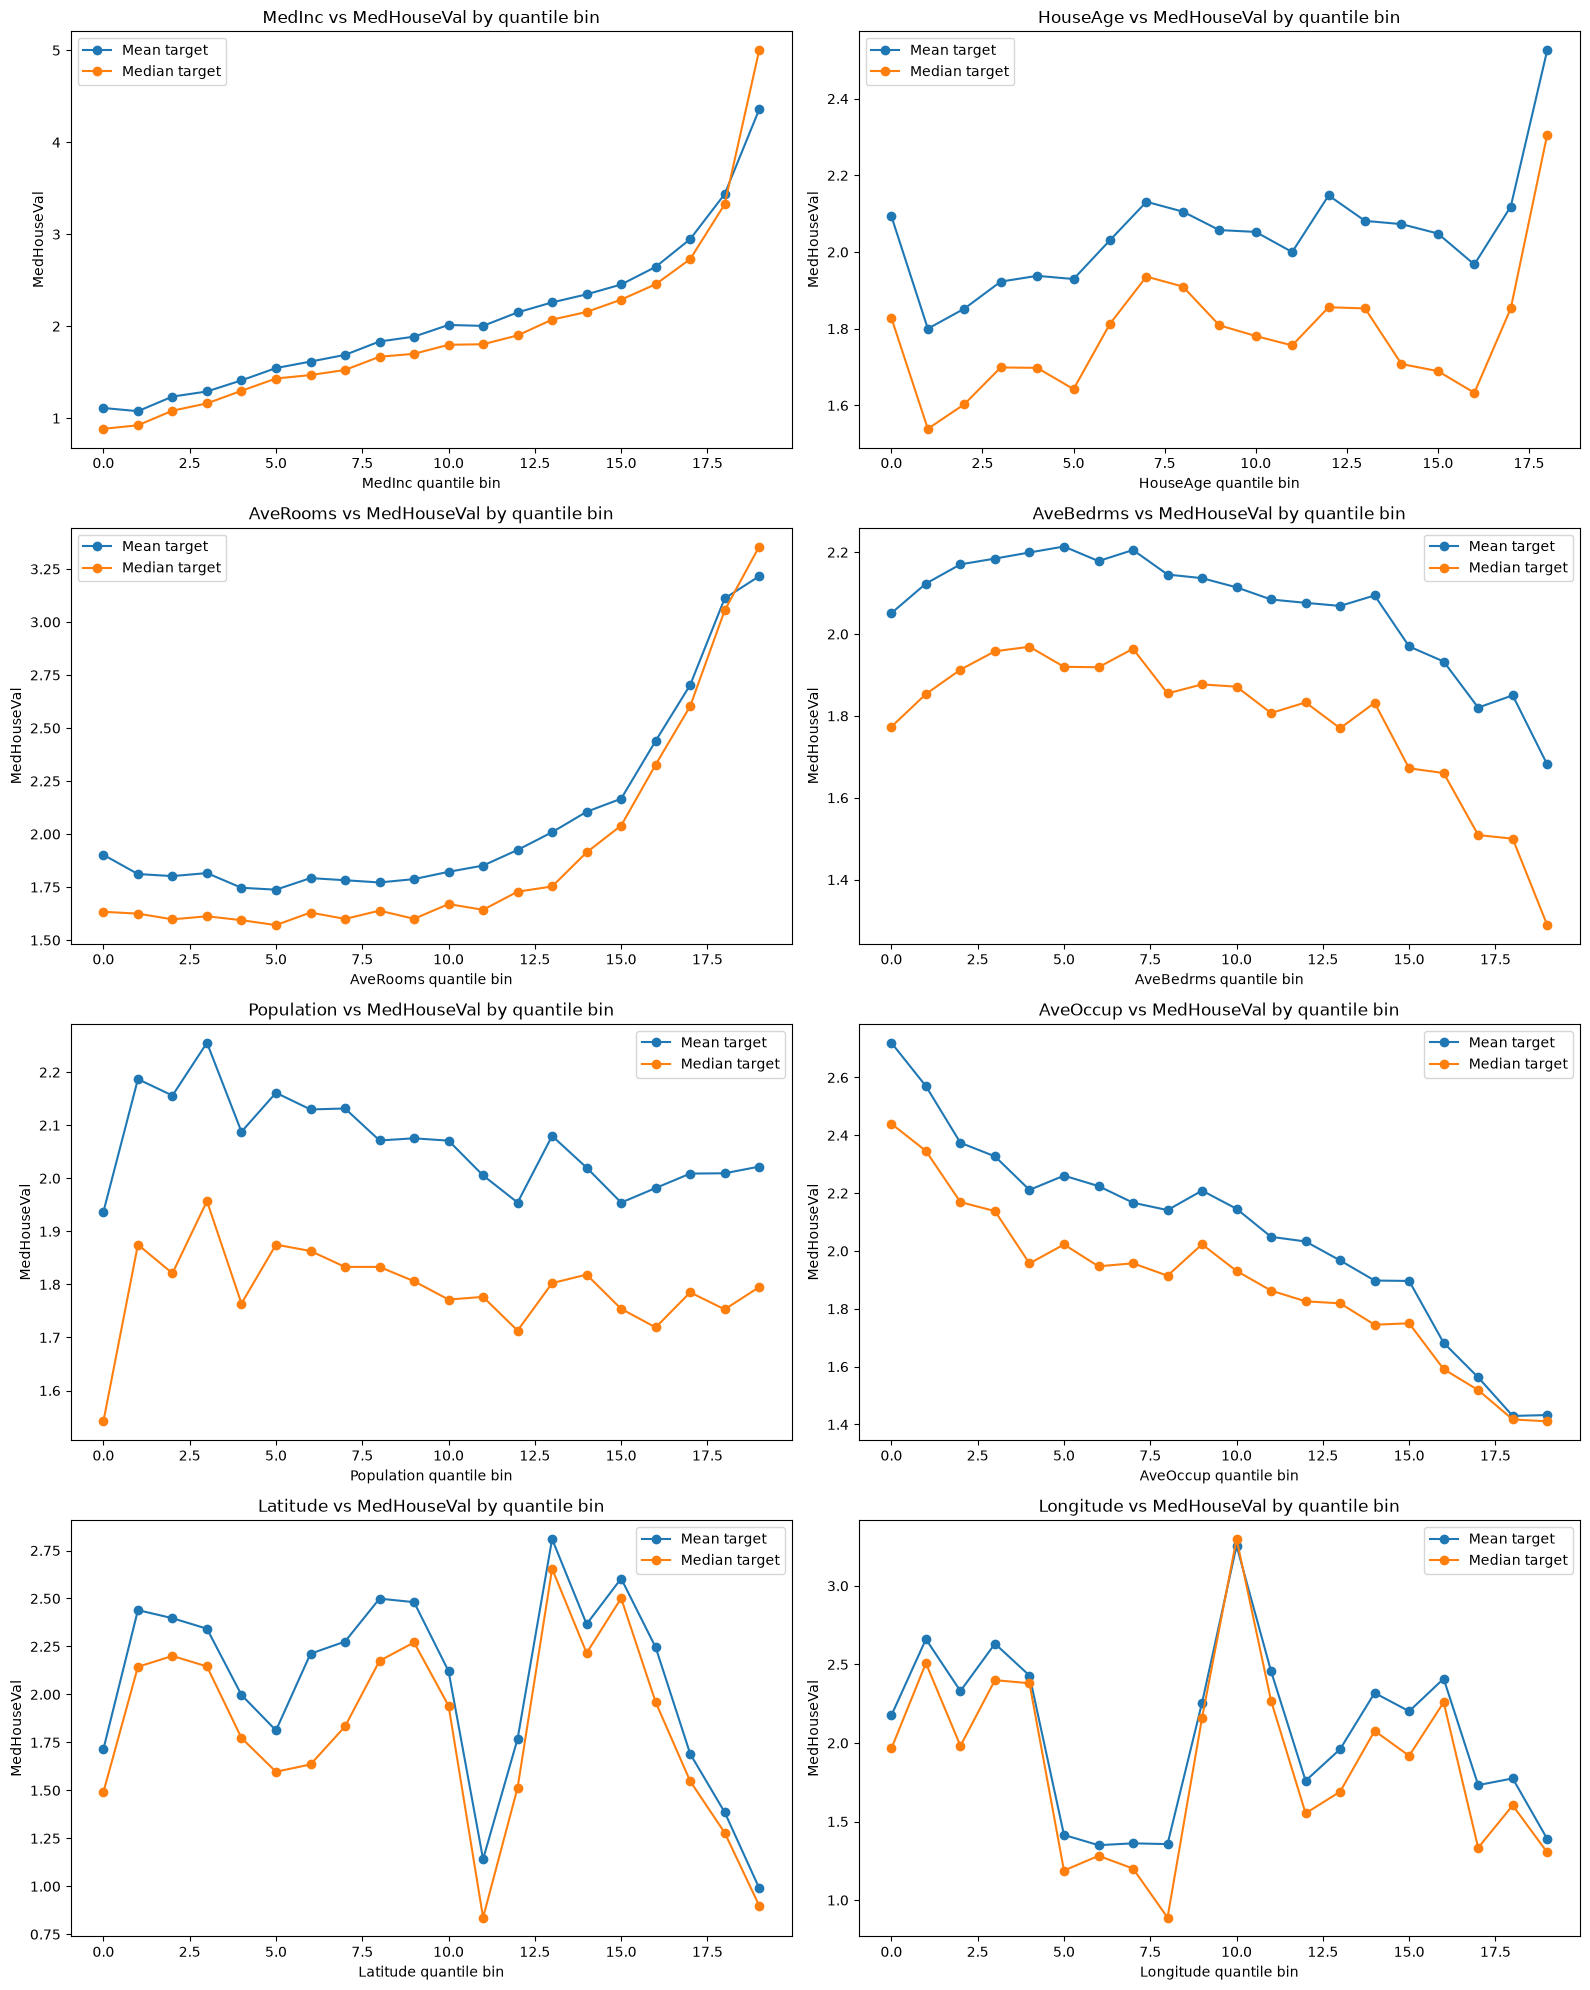

In [52]:
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.ravel()

for ax, feature in zip(axes, features):
    grouped = (
        eda_train
        .assign(feature_bin=pd.qcut(
            eda_train[feature],
            q=20,
            duplicates="drop"
        ))
        .groupby("feature_bin", observed=True)["MedHouseVal"]
        .agg(["mean", "median", "count"])
        .reset_index()
    )

    x = range(len(grouped))

    ax.plot(x, grouped["mean"], marker="o", label="Mean target")
    ax.plot(x, grouped["median"], marker="o", label="Median target")

    ax.set_title(f"{feature} vs MedHouseVal by quantile bin")
    ax.set_xlabel(f"{feature} quantile bin")
    ax.set_ylabel("MedHouseVal")
    ax.legend()

plt.tight_layout()
plt.show()

# 1. Feature-by-feature analysis
1. MedInc, strong positive relationship
Strongest visible trend
- Both mean and median house values rise as the income quantile increases.
- The increase becomes steeper in the upper income bins.
- This suggests a nonlinear relationship, with higher-income groups associated with disproportionately higher house values.
- The mean reaches about 4.4, while the median reaches 5.0 in the highest bin. The target cap affects interpretation at the upper end.
EDA implication: income is a strong candidate for predicting house value. Test whether a linear model captures the curvature adequately.

2. HouseAge, weak and irregular relationship
- Mean house values fluctuate across most bins, generally around 1.8 to 2.2.
- The median follows a similarly irregular pattern.
- The final bin rises sharply, but this alone does not establish a consistent trend across house ages.
EDA implication: house age alone does not show a clear monotonic relationship in these summaries. Investigate interactions with location and income.

3. AveRooms, nonlinear positive relationship at the upper end
- House values remain relatively flat across much of the lower and middle bins.
- Both mean and median rise sharply in the upper bins.
- This suggests a nonlinear pattern, but the highest bins might contain unusual observations or a different mix of census block groups.
EDA implication: inspect the feature's bin boundaries and observation counts. Check whether extreme room averages are influencing the upper-bin results.

4. AveBedrms, negative trend at the upper end
- House values rise slightly in the early bins.
- After the middle bins, both mean and median generally decline.
- The decline becomes more pronounced in the highest bins.
EDA implication: the relationship is nonlinear and potentially influenced by unusual bedroom-to-household ratios. Investigate extreme observations before interpreting this as a meaningful housing pattern.

5. Population, weak and irregular relationship
- Mean house values fluctuate without a consistent increase or decrease.
- Median house values also move irregularly.
- The first bin has a particularly low median, followed by a jump in the next bin.
EDA implication: population alone appears to have limited explanatory value in these summaries. Check bin counts and possible outliers.

6. AveOccup, clear negative relationship
Strong visible trend
- Both mean and median house values decrease as occupancy quantiles increase.
- The trend is fairly consistent across the bins.
- The mean and median converge in the highest bins, with house values around 1.4.
EDA implication: higher average occupancy is associated with lower house values. This aligns with your earlier scatter plot. Check whether extreme occupancy values affect the lowest bins.

7. Latitude, strong but irregular geographic pattern
- House values vary substantially across latitude bins.
- There are pronounced peaks and troughs, rather than a steady increase or decrease.
- The sharp drop around bin 11 and peaks around bins 13 and 15 suggest different geographic regions have different price levels.
EDA implication: latitude captures geographic structure, but a single latitude coordinate does not describe location fully. Examine latitude and longitude together.

8. Longitude, strong but irregular geographic pattern
- House values show large changes between neighboring quantile bins.
- The prominent peak near bin 10 suggests a high-value geographic concentration.
- Several other bins have substantially lower values.
EDA implication: longitude captures geographic variation, but the relationship is not monotonic. A two-dimensional location analysis is more informative than interpreting longitude alone.

# 2.  What do the mean and median differences tell you?
Look at the gap between the blue and orange lines.
- Mean above median: often indicates a right-skewed distribution, where some high house values pull the mean upward.
- Mean close to median: suggests less difference between the two measures of central tendency, although it does not prove a symmetric distribution.
- Both lines moving together: the trend is visible in both the average and the typical observation.
- Sudden jumps or drops: the feature might have a nonlinear relationship with the target, or the bins might contain different types of observations.
Your MedInc and AveOccup plots show especially consistent trends. Your latitude and longitude plots show why geographic features need a different approach.

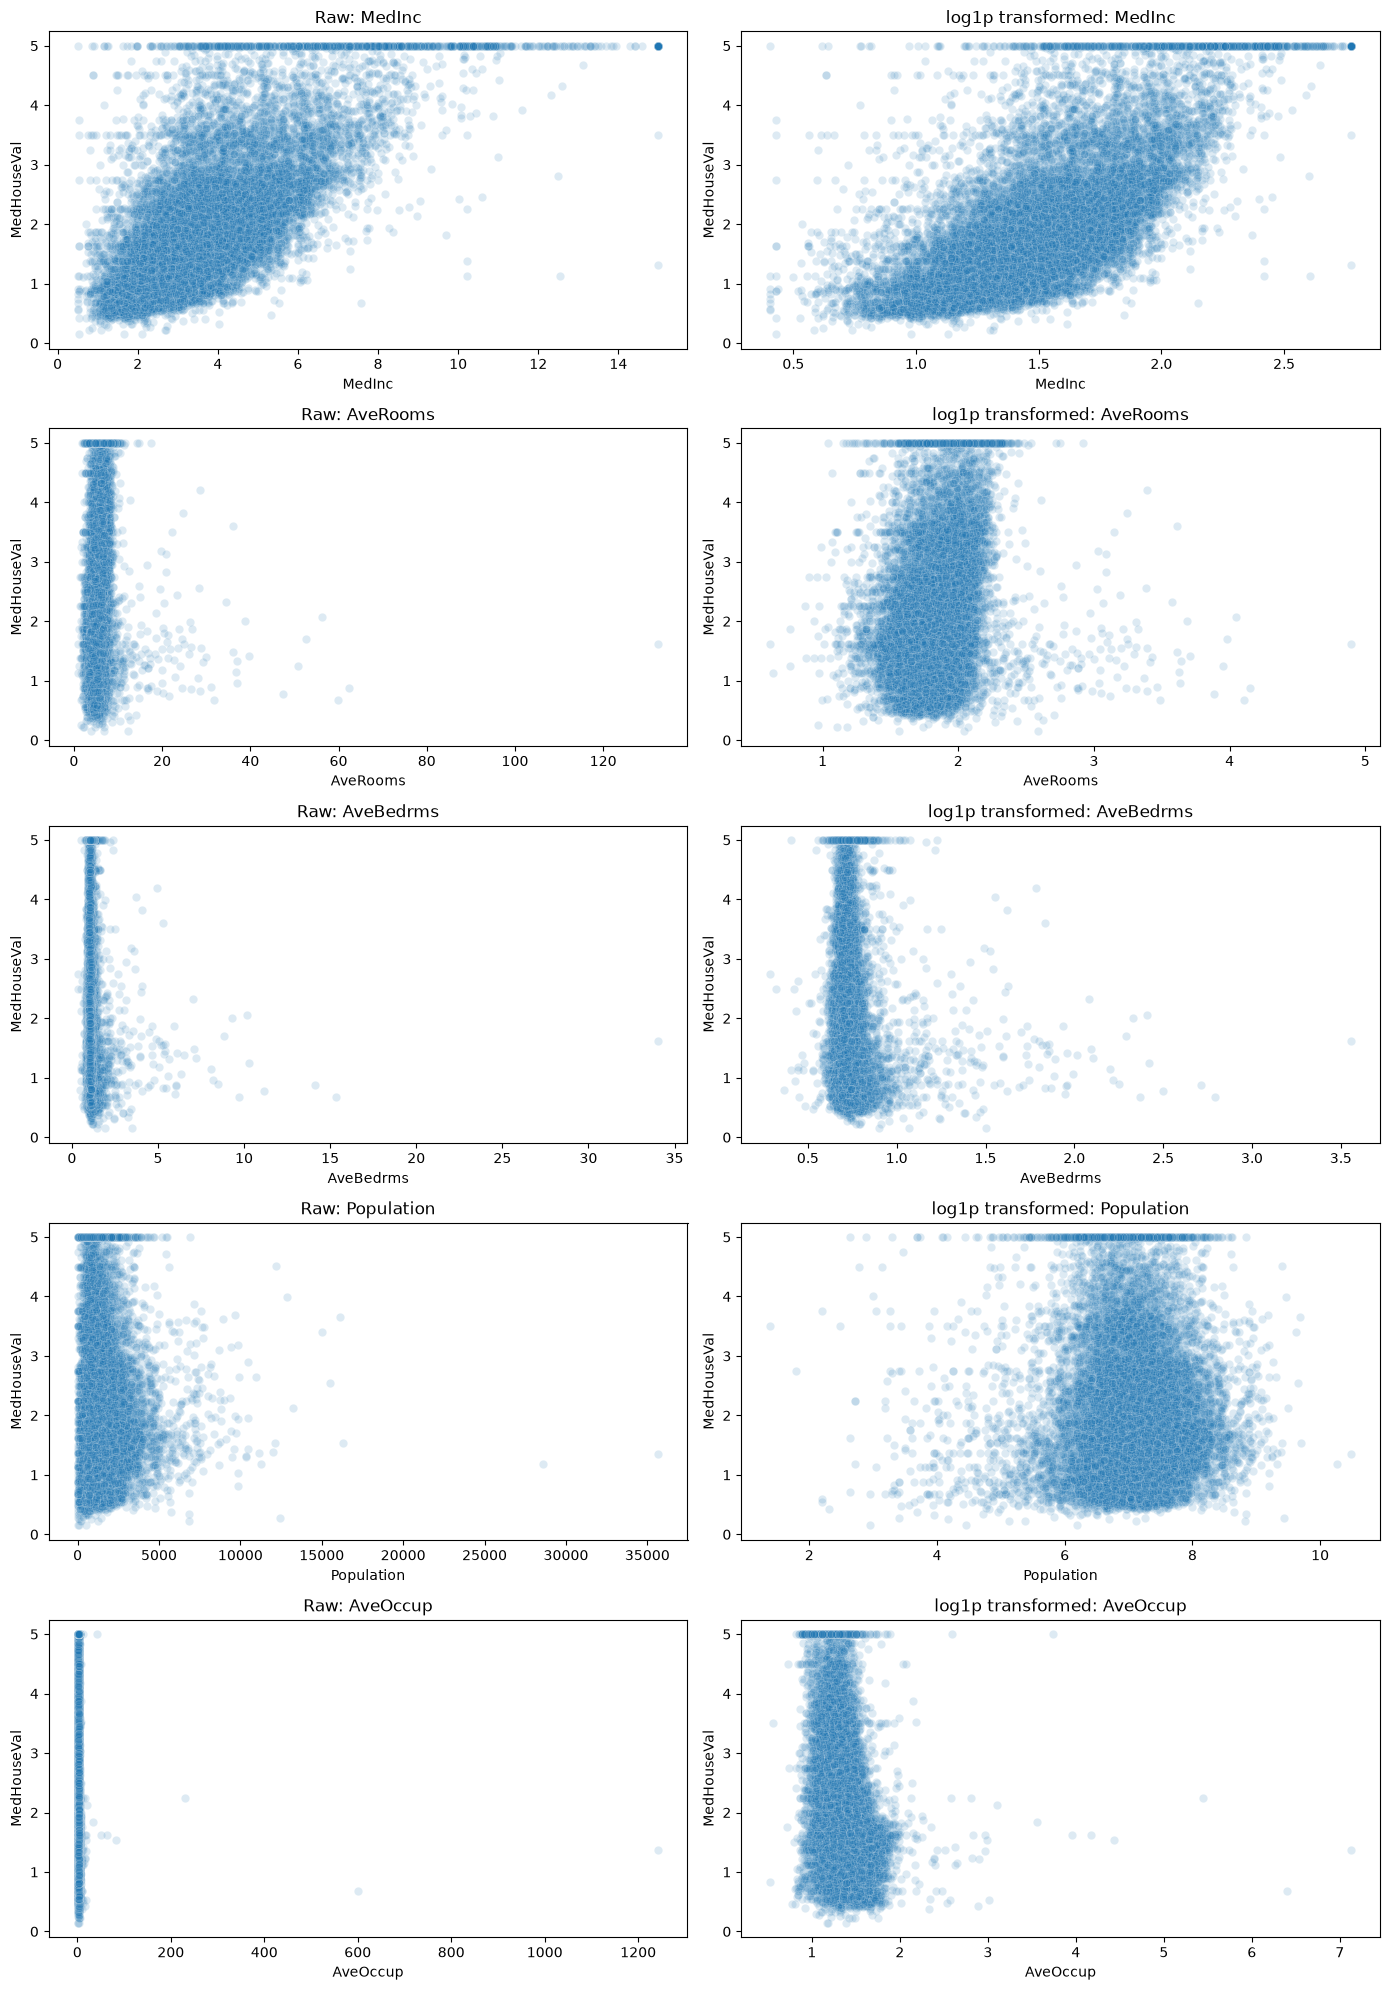

In [53]:
transformed_features = ["MedInc", "AveRooms", "AveBedrms", "Population", "AveOccup"]

fig, axes = plt.subplots(
    len(transformed_features),
    2,
    figsize=(14, 4 * len(transformed_features))
)

for row, feature in enumerate(transformed_features):
    sns.scatterplot(
        data=eda_train,
        x=feature,
        y="MedHouseVal",
        alpha=0.15,
        ax=axes[row, 0]
    )
    axes[row, 0].set_title(f"Raw: {feature}")

    sns.scatterplot(
        x=np.log1p(eda_train[feature]),
        y=eda_train["MedHouseVal"],
        alpha=0.15,
        ax=axes[row, 1]
    )
    axes[row, 1].set_title(f"log1p transformed: {feature}")

plt.tight_layout()
plt.show()

The raw plot shows a clear positive relationship with house value. The log1p plot of MedInc compresses higher income values and spreads out the lower values.<br>
the transformed plot of AveRooms,AveBedrms,population,AveOccup reveals the main cluster more clearly, but a clear linear relationship with house value is still absent.

Do not conclude that a transformation should be used in the model merely because the plot looks better. Record it as a hypothesis to test later inside a pipeline.



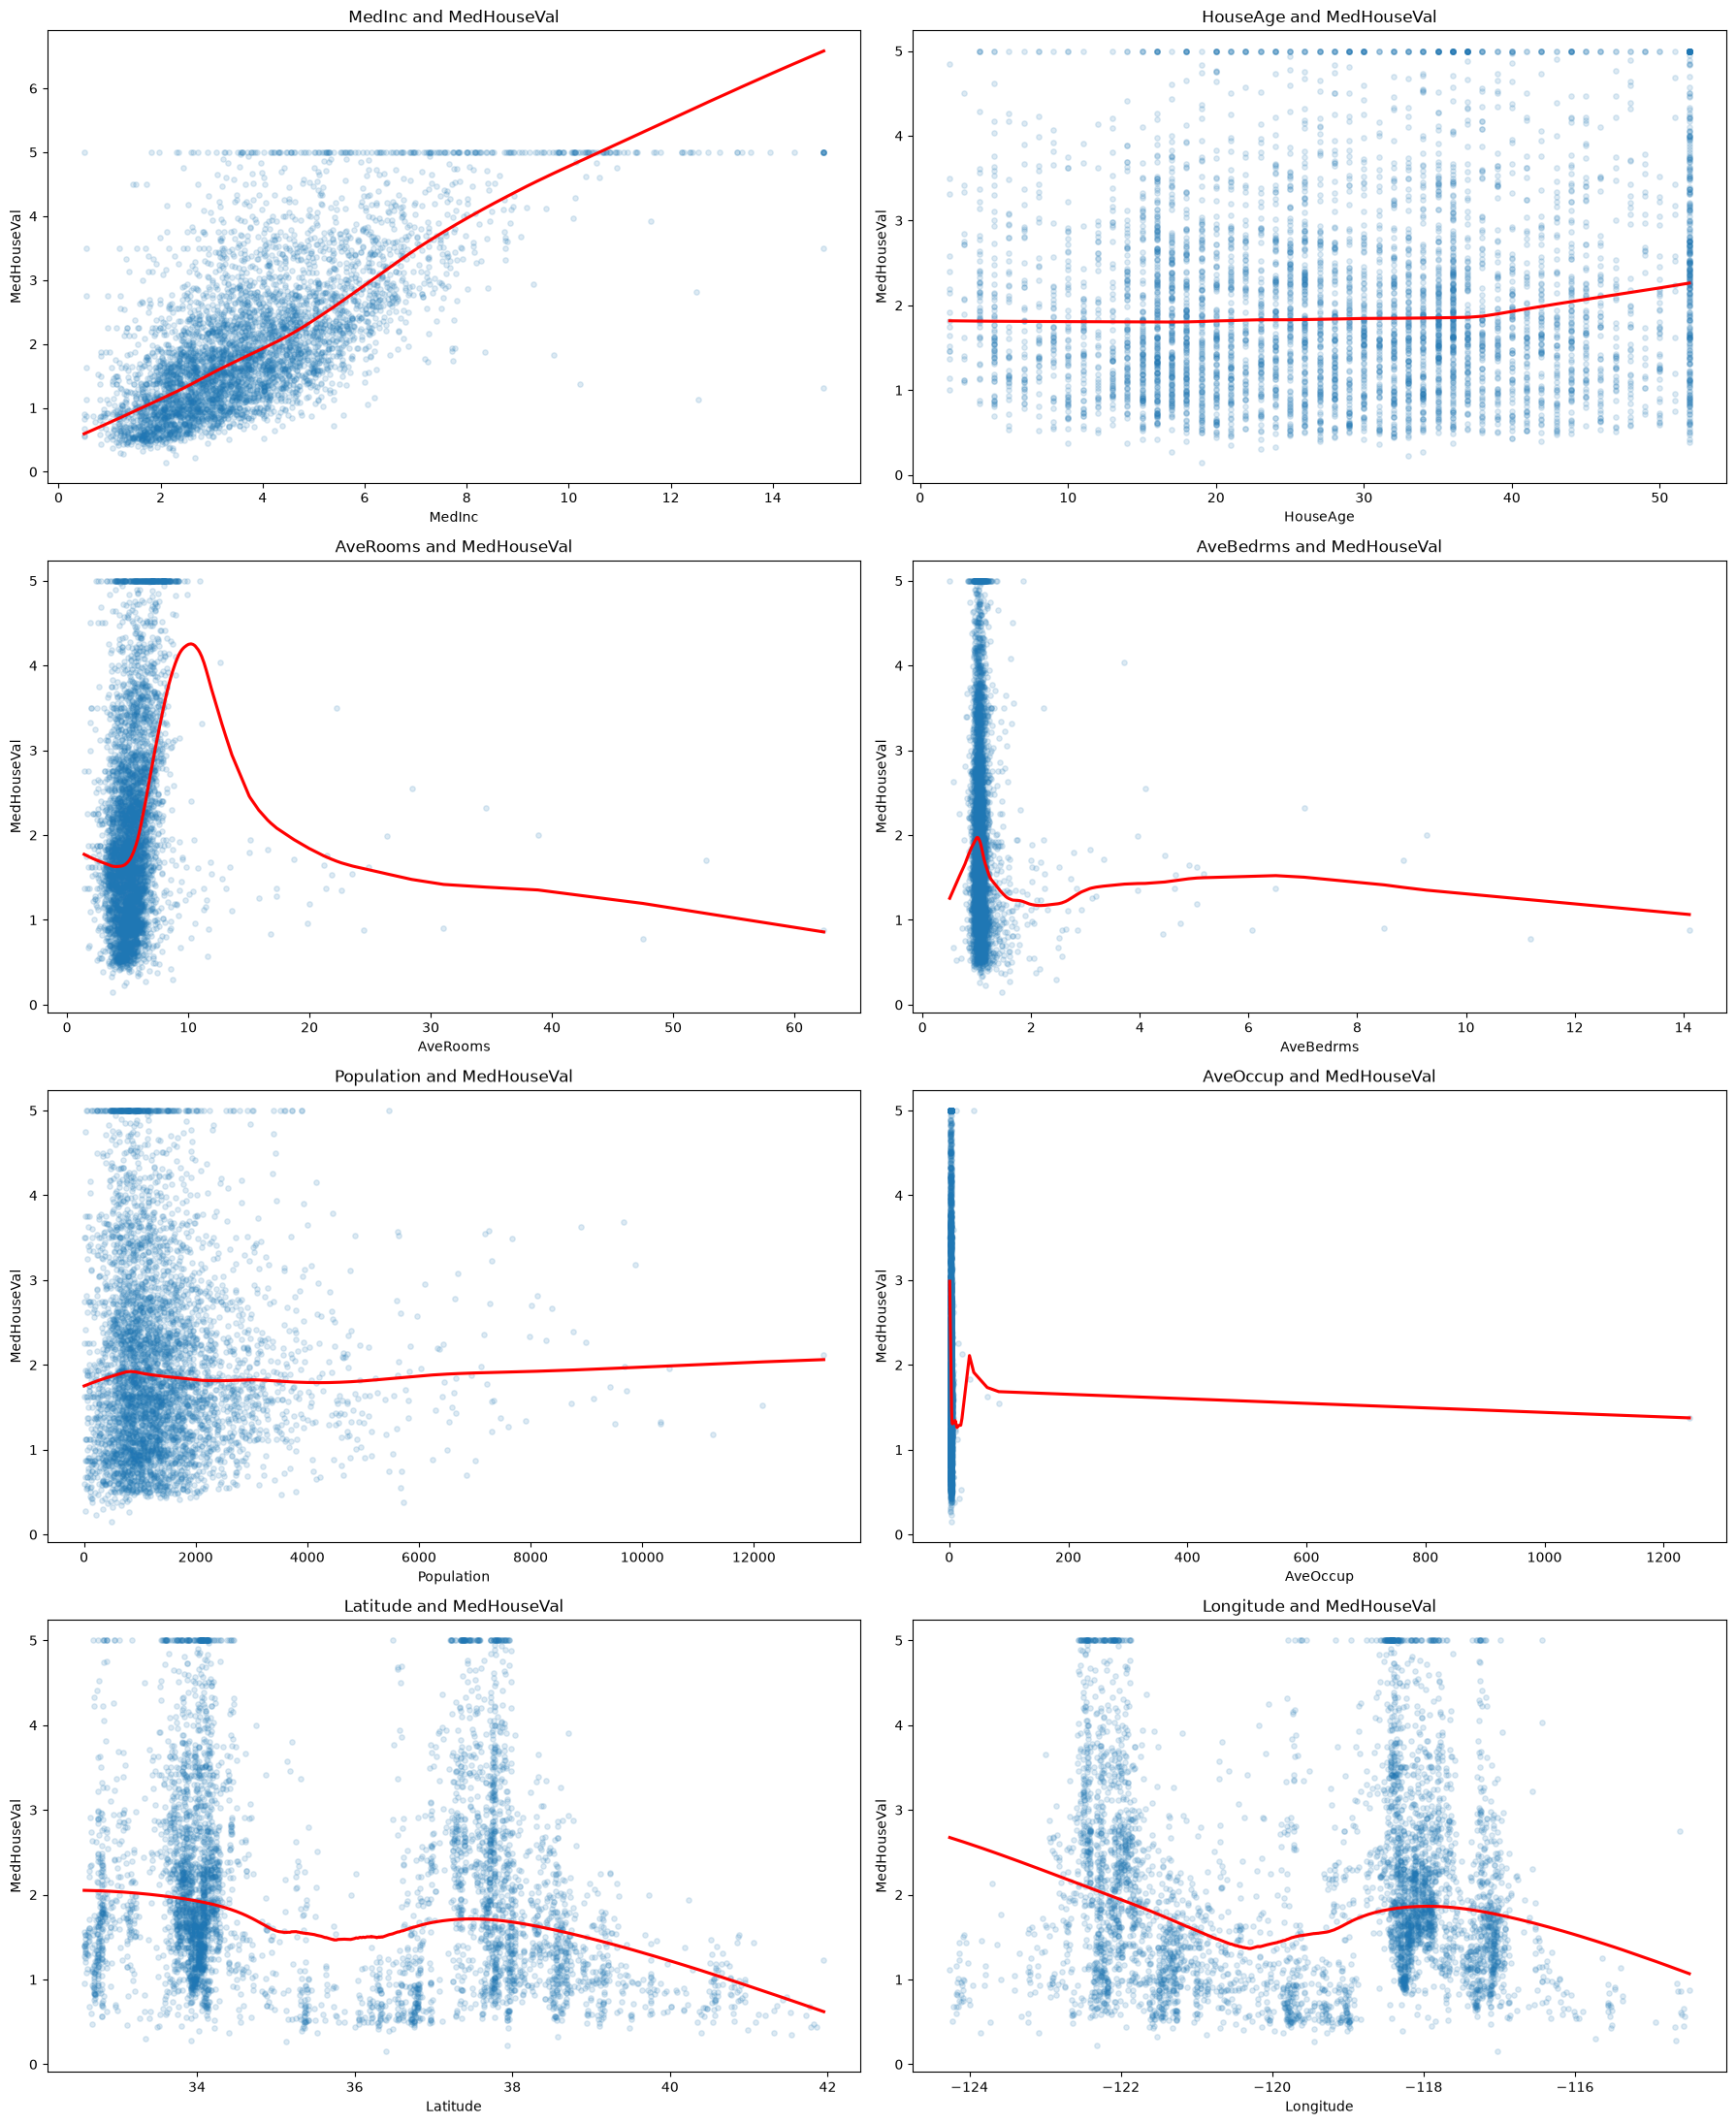

In [ ]:

plot_data = eda_train.sample(
    min(5000, len(eda_train)),
    random_state=RANDOM_STATE
# Keep observations at or below the training 99th percentile for every feature
p99 = eda_train[features].quantile(0.99)

plot_data = eda_train.loc[
    eda_train[features].le(p99).all(axis=1)
].sample(
    min(5000, len(eda_train)),
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(4, 2, figsize=(18, 22))
axes = axes.ravel()

for ax, feature in zip(axes, features):
    sns.regplot(
        data=plot_data,
        x=feature,
        y="MedHouseVal",
        lowess=True,
        scatter_kws={"alpha": 0.15, "s": 15},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"{feature} and MedHouseVal")
    ax.set_xlabel(feature)
    ax.set_ylabel("MedHouseVal")

plt.tight_layout()
plt.show()

# MedInc vs MedHouseVal Lmplot
 observation:
- Strong positive association: higher median income generally corresponds to higher median house value.
- Nonlinearity: the fitted curve rises at different rates across the income range. This suggests the relationship is not perfectly linear.
- Increasing spread: house values vary considerably at similar income levels.
- Target cap: many observations reach 5.0, limiting what the plot tells us about values above the cap.
The line also extends above 5.0 near the upper end of income. This is a key distinction: the fitted line estimates a trend, while the actual target values remain capped at 5.0. The line is not constrained to stay within the target's observed range.

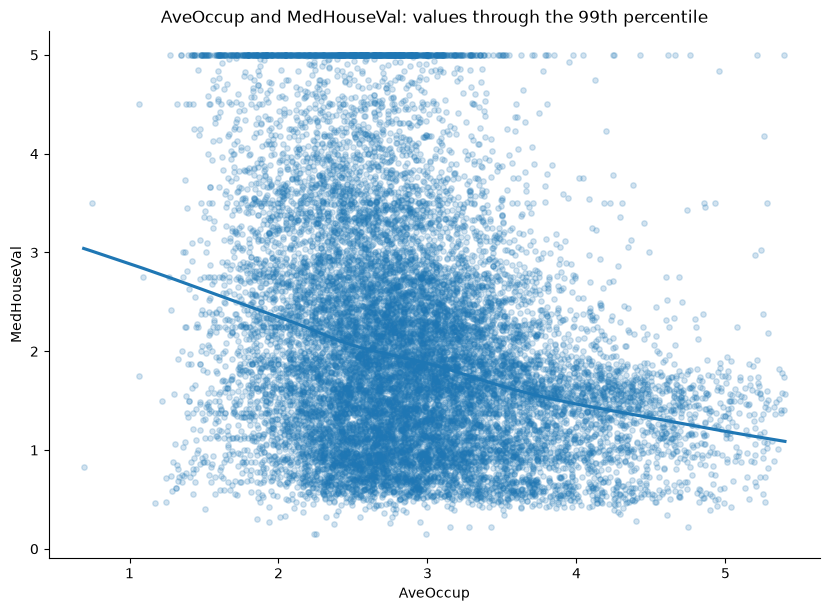

In [55]:
occupancy_plot = eda_train[eda_train["AveOccup"] <= eda_train["AveOccup"].quantile(0.99)]

sns.lmplot(
    data=occupancy_plot,
    x="AveOccup",
    y="MedHouseVal",
    lowess=True,
    scatter_kws={"alpha": 0.2, "s": 15},
    height=6,
    aspect=1.4
)
plt.title("AveOccup and MedHouseVal: values through the 99th percentile")
plt.show()

lmplot showing observations up to the 99th percentile of AveOccup.

observation:
- Negative relationship: the fitted line slopes downward. Higher average occupancy tends to be associated with lower median house values.
- High variability: at similar occupancy levels, house values vary widely. Occupancy alone does not explain much of the variation.
- Target cap: the horizontal band at 5.0 shows the capped house values.
- Nonlinear pattern: the fitted line appears curved, suggesting a straight line might not fully describe the relationship.
One important detail: your plot excludes occupancy values above the 99th percentile. This improves visibility of the main distribution, but it hides the most extreme 1% of observations. Keep those observations in your original dataset while you investigate them separately.

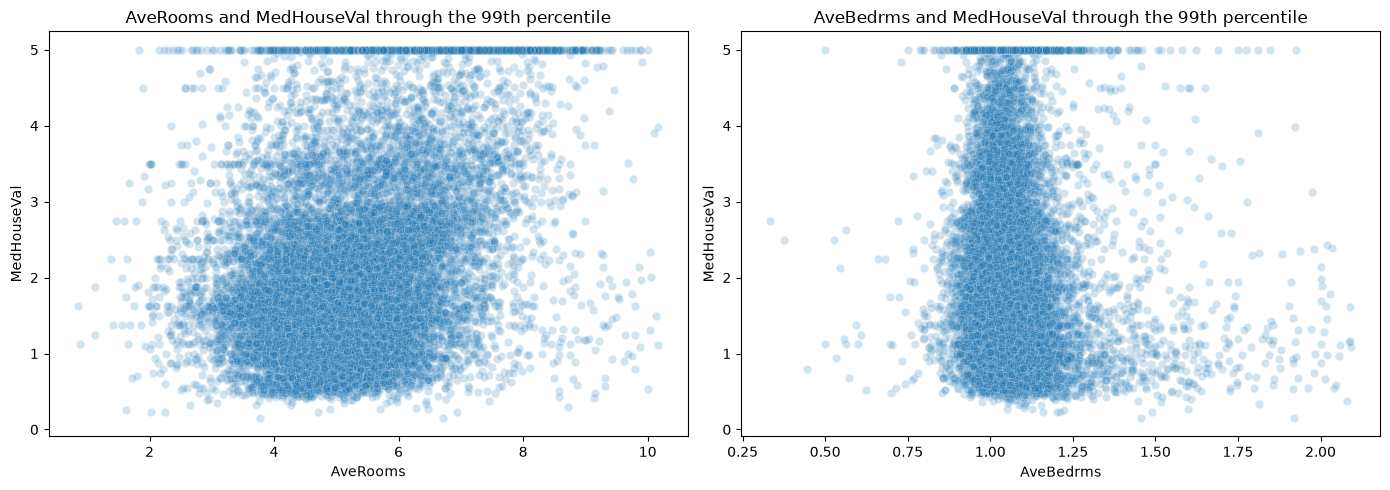

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=eda_train[eda_train["AveRooms"] <= eda_train["AveRooms"].quantile(0.99)],
    x="AveRooms",
    y="MedHouseVal",
    alpha=0.2,
    ax=axes[0]
)
axes[0].set_title("AveRooms and MedHouseVal through the 99th percentile")

sns.scatterplot(
    data=eda_train[eda_train["AveBedrms"] <= eda_train["AveBedrms"].quantile(0.99)],
    x="AveBedrms",
    y="MedHouseVal",
    alpha=0.2,
    ax=axes[1]
)
axes[1].set_title("AveBedrms and MedHouseVal through the 99th percentile")

plt.tight_layout()
plt.show()

# important interpretation
up until this point, the notebook has performed data inspection and leakage-safe exploratory analysis, but it has not yet applied production preprocessing such as:

imputation,
standardization,
feature encoding,
feature removal,
outlier removal,
winsorization,
or permanent log transformations.
The income_band, uncapped-target subset, IQR flags, and log1p plots are currently EDA or sensitivity-analysis artifacts, not final model features or preprocessing rules.